# Network Intrusion Detection using Machine Learning

This project processes the CICIDS2017 dataset, performs feature selection,
and trains a Random Forest classifier to detect malicious network traffic.

In [1]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)


In [2]:
files = [
    r"C:\Users\rafat\Downloads\archive\Monday-WorkingHours.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Tuesday-WorkingHours.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Wednesday-workingHours.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Friday-WorkingHours-Morning.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    r"C:\Users\rafat\Downloads\archive\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"
]

# Combine all files
df = pd.concat(
    [pd.read_csv(f, low_memory=False) for f in files],
    ignore_index=True
)

print("Dataset shape:", df.shape)

Dataset shape: (2830743, 79)


In [3]:

# Replace infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove rows containing missing values
df.dropna(inplace=True)

# Create binary target:
# 0 = Benign, 1 = Attack
df['Binary_Label'] = (
    df[' Label'].str.strip().str.lower() != 'benign'
).astype(int)

# Remove the original target column
df.drop(columns=[' Label'], inplace=True)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df['Binary_Label'].value_counts())
print("\nClass proportions:")
print(df['Binary_Label'].value_counts(normalize=True))

# Save cleaned dataset
df.to_csv("final_work.csv", index=False)

print("\nDataset saved as final_work.csv")


Dataset shape: (2827876, 79)

Class distribution:
Binary_Label
0    2271320
1     556556
Name: count, dtype: int64

Class proportions:
Binary_Label
0    0.803189
1    0.196811
Name: proportion, dtype: float64

Dataset saved as final_work.csv


In [4]:

# Load cleaned dataset
df = pd.read_csv("final_work.csv")

# Remove metadata that should not be used as model features
metadata_cols = [' Source IP', ' Timestamp']
df.drop(
    columns=[c for c in metadata_cols if c in df.columns],
    inplace=True
)

# Separate target and features
y = df['Binary_Label']
X = df.drop(columns=['Binary_Label'])

# Keep numeric features only
non_numeric_cols = X.select_dtypes(
    exclude=[np.number]
).columns.tolist()

if non_numeric_cols:
    print("Non-numeric columns removed:", non_numeric_cols)
    X = X.drop(columns=non_numeric_cols)

print("Initial number of numeric features:", X.shape[1])

# IMPORTANT: Split BEFORE feature selection
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

# -------------------------------------------------
# STEP A: Remove constant features using TRAIN only
# -------------------------------------------------
constant_cols = [
    col for col in X_train.columns
    if X_train[col].nunique(dropna=False) <= 1
]

X_train = X_train.drop(columns=constant_cols)
X_test = X_test.drop(columns=constant_cols)

print("\nConstant features removed:", len(constant_cols))

# -------------------------------------------------
# STEP B: Correlation-based feature selection
# Fit correlation matrix using TRAIN only
# -------------------------------------------------
corr_matrix = X_train.corr().abs()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

threshold = 0.90

to_drop = [
    column
    for column in upper.columns
    if (upper[column] > threshold).any()
]

print("Highly correlated features removed:", len(to_drop))

# Apply exactly the same feature selection to both sets
X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

print("\nFinal training feature count:", X_train.shape[1])
print("Final testing feature count:", X_test.shape[1])

assert list(X_train.columns) == list(X_test.columns)

print("\nFeature selection completed without using test-set correlations.")


Initial number of numeric features: 78

Training samples: 2262300
Testing samples: 565576

Training class distribution:
Binary_Label
0    1817055
1     445245
Name: count, dtype: int64

Testing class distribution:
Binary_Label
0    454265
1    111311
Name: count, dtype: int64

Constant features removed: 8
Highly correlated features removed: 31

Final training feature count: 39
Final testing feature count: 39

Feature selection completed without using test-set correlations.


In [5]:

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train only on training data
rf.fit(X_train, y_train)

# Predictions at the default threshold
y_pred = rf.predict(X_test)

# Probability that a flow is an attack (class 1)
y_prob = rf.predict_proba(X_test)[:, 1]

print("Random Forest training completed.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Random Forest training completed.
Training samples: 2262300
Testing samples: 565576


RANDOM FOREST - INTRUSION DETECTION RESULTS
Accuracy:               0.9990
Balanced Accuracy:      0.9984
Macro F1-score:         0.9984
Attack Precision:       0.9973
Attack Recall:          0.9975
Attack F1-score:        0.9974
Average Precision (AP): 0.9983

Classification Report:
              precision    recall  f1-score   support

      Benign     0.9994    0.9993    0.9994    454265
      Attack     0.9973    0.9975    0.9974    111311

    accuracy                         0.9990    565576
   macro avg     0.9983    0.9984    0.9984    565576
weighted avg     0.9990    0.9990    0.9990    565576

Confusion Matrix:
[[453963    302]
 [   283 111028]]

True Negatives (TN):  453963
False Positives (FP): 302
False Negatives (FN): 283
True Positives (TP):  111028
False Positive Rate:  0.0007


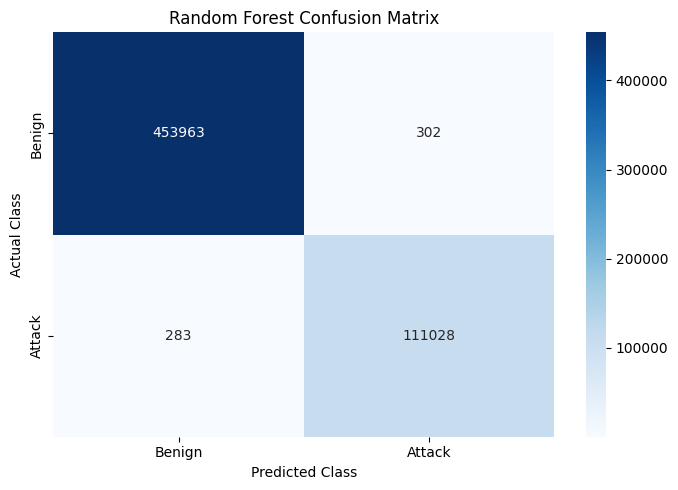

In [8]:

# -------------------------------------------------
# Overall metrics
# -------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)

balanced_acc = balanced_accuracy_score(
    y_test, y_pred
)

macro_f1 = f1_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

attack_precision = precision_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

attack_recall = recall_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

attack_f1 = f1_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

average_precision = average_precision_score(
    y_test, y_prob
)

print("=" * 55)
print("RANDOM FOREST - INTRUSION DETECTION RESULTS")
print("=" * 55)

print(f"Accuracy:               {accuracy:.4f}")
print(f"Balanced Accuracy:      {balanced_acc:.4f}")
print(f"Macro F1-score:         {macro_f1:.4f}")
print(f"Attack Precision:       {attack_precision:.4f}")
print(f"Attack Recall:          {attack_recall:.4f}")
print(f"Attack F1-score:        {attack_f1:.4f}")
print(f"Average Precision (AP): {average_precision:.4f}")

# -------------------------------------------------
# Per-class precision, recall and F1
# -------------------------------------------------
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Benign', 'Attack'],
        digits=4,
        zero_division=0
    )
)

# -------------------------------------------------
# Confusion matrix
# Rows = actual, columns = predicted
# -------------------------------------------------
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print(f"\nTrue Negatives (TN):  {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP):  {tp}")

# False positive rate: proportion of benign flows
# incorrectly classified as attacks
false_positive_rate = (
    fp / (fp + tn) if (fp + tn) > 0 else 0
)

print(f"False Positive Rate:  {false_positive_rate:.4f}")

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Attack'],
    yticklabels=['Benign', 'Attack']
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


In [9]:
import joblib

joblib.dump(rf, "rf_model.pkl")

print("Model saved as rf_model.pkl")

Model saved as rf_model.pkl
